# A measured cobalt phosphide particle in three dimensions

This notebook actively reconstructs all 74 measured HAADF projections and all 128 independent cross-sections. It compares the fresh local implementation with this task's captured **modern Tomviz** run, not with unavailable actual volume truth. The 2016 dataset paper provides acquisition context; the preserved source implementation is a later Tomviz revision. No atomic-resolution or absolute mass-density claim is made.

The observations are aligned author-supplied experimental frames. Two blank/backlash views are removed; a fixed 1152-square crop is averaged in nonoverlapping 9 by 9 detector blocks. Sampling is nominally 6.39 nm. Independent ray geometry, adjoint, directional-gradient and positivity tests accompany numerical source parity.

In [1]:
from pathlib import Path
import os,sys,time,json,subprocess
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.physics_model import parallel_ray
from src.solvers import reconstruct
from src.visualization import metrics,figures,export
measurements,angles=load_data(ROOT/'data/raw_data.npz')
with np.load(ROOT/'notebooks/reference_outputs/upstream_reconstruction.npz',allow_pickle=False) as f: reference=f['reconstruction'][0]
print('Measured array:',measurements.shape,'retained angles:',angles)


Measured array: (128, 128, 74) retained angles: [-75. -73. -71. -69. -67. -65. -63. -61. -59. -57. -55. -53. -51. -49.
 -47. -45. -43. -41. -39. -37. -35. -33. -31. -29. -27. -25. -23. -21.
 -19. -17. -15. -13. -11.  -9.  -7.  -5.  -3.  -1.   1.   3.   5.   7.
   9.  11.  13.  15.  17.  19.  21.  27.  29.  31.  33.  35.  37.  39.
  41.  43.  45.  47.  49.  51.  53.  55.  57.  59.  61.  63.  65.  67.
  69.  71.  73.  75.]


## Forward physics and selected inverse

For each horizontal slice, the data vector b contains angle-major detector rays. Matrix A contains ray intersection lengths in voxel units. The scattering response q satisfies b approximately equals Aq. Pixel centers are half-integer coordinates within [-64,64] squared; at angle a the projection normal is (cos a,sin a). Stored depth rows run opposite the physical depth coordinate.

We minimize one half of the unnormalised squared residual with 100 fixed positive Landweber steps, q <- max(0,q + 0.0001 A^T(b-Aq)), initialized at zero. The source's float32 stored volume and mixed-precision work-vector convention are preserved. Positivity is the only additional constraint. The missing wedge remains a physical limitation.

The next cell computes the complete selected benchmark path; archived arrays are used only for comparison.

In [2]:
start=time.perf_counter()
volume,history=reconstruct(measurements,angles)
runtime=time.perf_counter()-start
print('Fresh full-volume reconstruction seconds:',runtime)
print('Comparison with reproduced upstream method:',metrics(volume,reference))
print('Largest absolute source-parity difference:',float(np.max(abs(volume-reference))))
(ROOT/'output').mkdir(exist_ok=True)
np.savez_compressed(ROOT/'output/reconstruction.npz',reconstruction=volume[None])
proc=subprocess.run([sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')],capture_output=True,text=True)
print(proc.stdout)
assert proc.returncode==0,proc.stderr


Fresh full-volume reconstruction seconds: 168.3524247000023
Comparison with reproduced upstream method: {'ncc': 0.9999999999999994, 'nrmse': 0.0}
Largest absolute source-parity difference: 0.0


{"status": "pass", "passed": true, "metrics": {"ncc": 0.9999999999999981, "nrmse": 0.0, "projection_residual": 0.1438411360390179}, "thresholds": {"ncc": {"comparison": ">=", "boundary": 0.999999}, "nrmse": {"comparison": "<=", "boundary": 1e-05}, "projection_residual": {"comparison": "<=", "boundary": 0.1452795471782387}}, "errors": []}



## Actual comparisons and iteration sensitivity

All central-slice variants below are freshly reconstructed from the measured central slice. Their 10/30/100 iteration comparison illustrates the tradeoff between incomplete convergence and missing-wedge artifacts. It does not stand in for the full 128-cubed reconstruction above. Forward projections and signed measurement residuals reveal departures from the finite-support linear model; agreement with a method reference alone cannot establish physical accuracy.

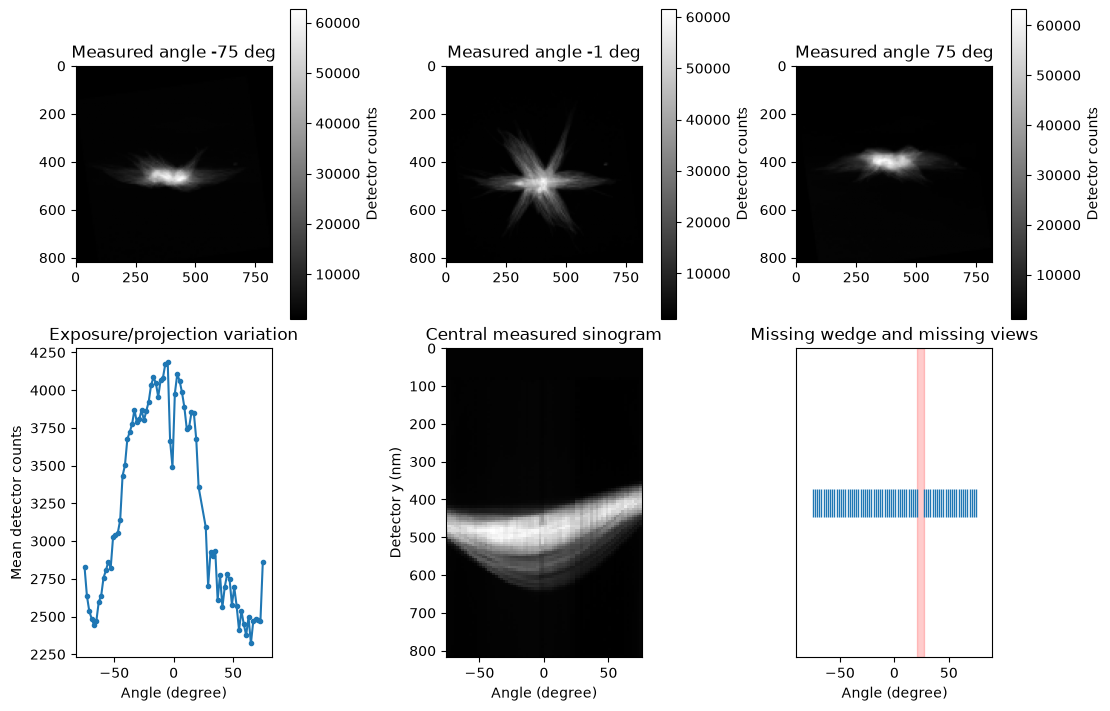

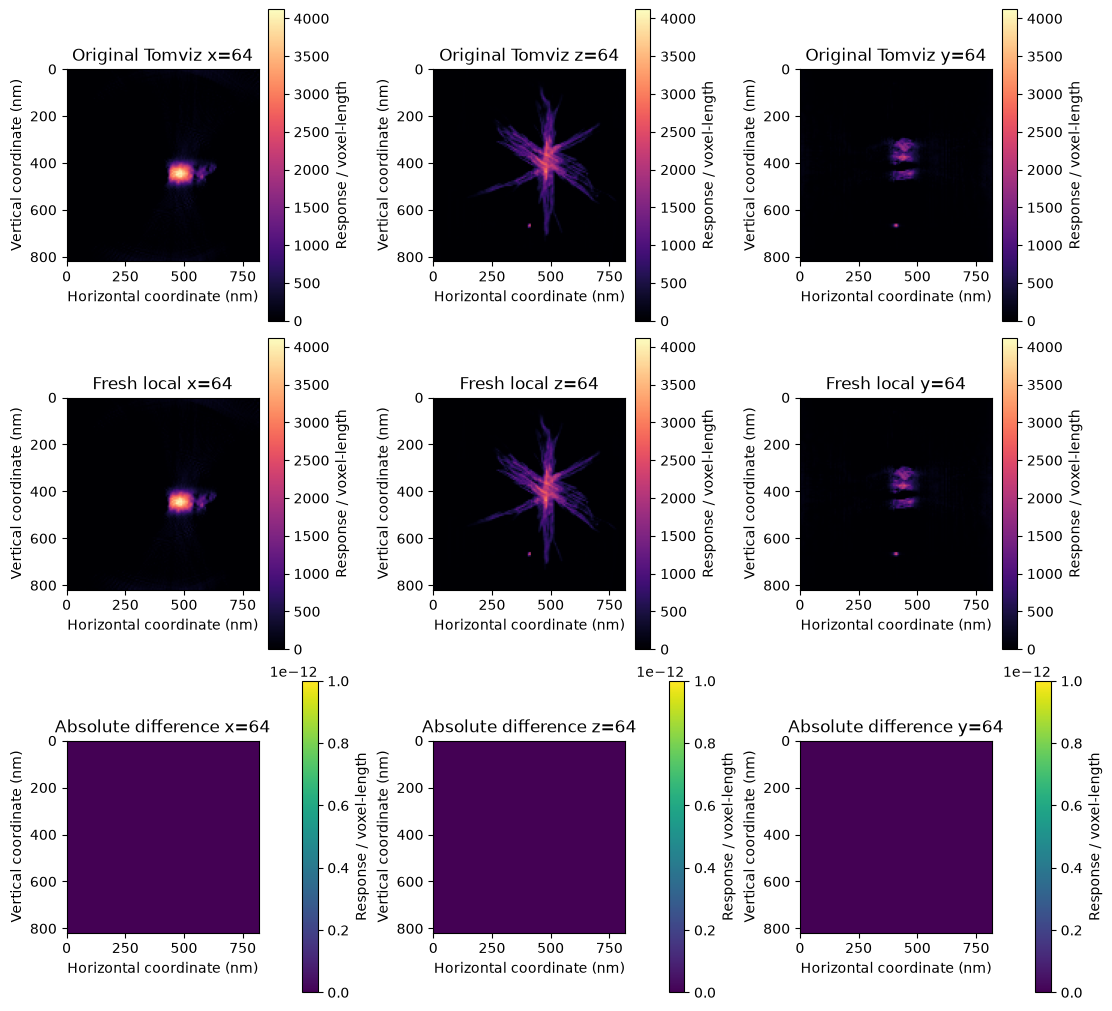

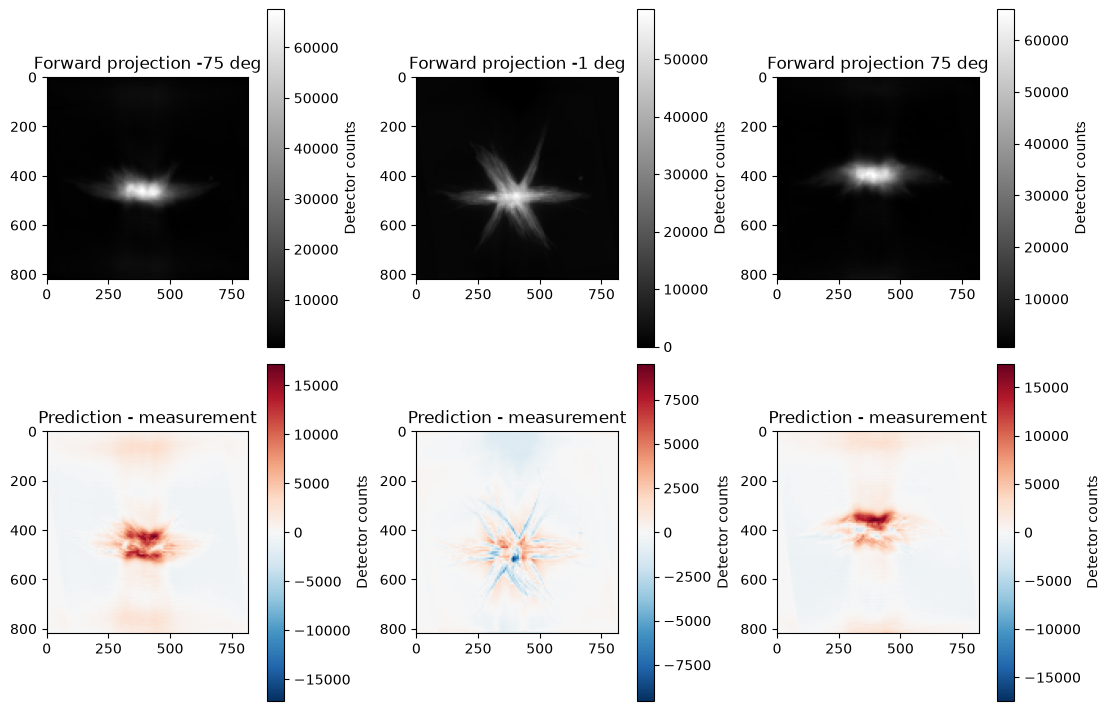

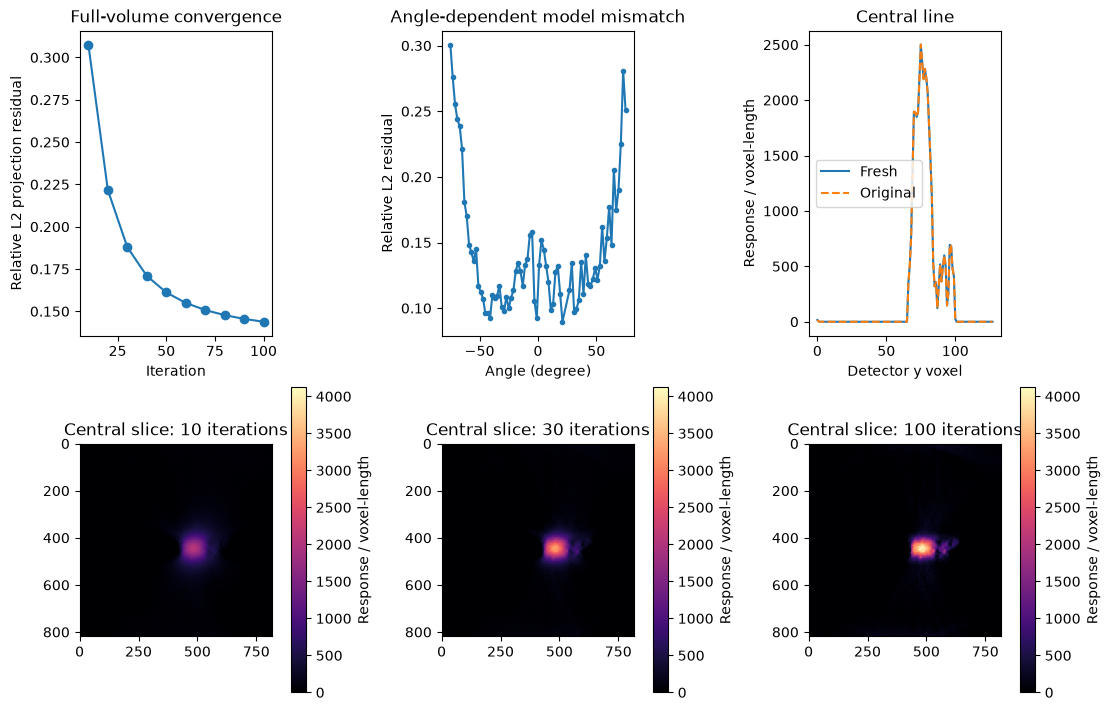

Final relative L2 projection residual: 0.14384113582004115


In [3]:
variants={}
for iterations in [10,30,100]:
    variants[iterations],_=reconstruct(measurements[64:65],angles,iterations=iterations,record_every=0)
matrix=parallel_ray(128,1.,angles,128,1.)
plots,prediction=figures(measurements,angles,volume,reference,history,matrix,variants)
for name,fig in plots.items():
    display(fig)
    plt.close(fig)
print('Final relative L2 projection residual:',float(np.linalg.norm(prediction-measurements)/np.linalg.norm(measurements)))
if os.environ.get('PRIVATE_FIGURES'):
    export(plots,os.environ['PRIVATE_FIGURES'],dict(measurements=measurements,angles=angles,fresh_volume=volume,upstream_volume=reference,forward_projections=prediction,history=history,**{'fresh_central_'+str(k):v for k,v in variants.items()}))


## Interpretation and limits

The three orthogonal sections compare identical coordinates and intensity scales. The zero or numerical-scale difference panels establish implementation fidelity. The projections, their angle-dependent residuals, and the central-slice iteration comparison examine convergence and acquisition mismatch separately.

These data contain an actual measured nanoparticle but no independent three-dimensional density truth. The hidden method reference supports reproducibility rather than a claim of true volumetric accuracy. Finite tilt coverage elongates structures along weakly observed directions, and nominal detector sampling does not establish the spatial resolution of the reconstructed material.